# Quadratic Penalty and Augmented Lagrangian Methods

Compare exact quadratic-penalty subproblem solves and the method of multipliers for a strictly convex equality-constrained quadratic. Use the analytical KKT solution as a reference for primal feasibility, objective convergence and multiplier convergence.

[Technical notes](../docs/penalty_and_augmented_lagrangian.md) · [Saved figures](../results/penalty_and_augmented_lagrangian/)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Equality-constrained objective

$$\min f(x)=x_1^2+2x_2^2+3x_3^2,\qquad h(x)=x_1+x_2+x_3-1=0.$$

In [2]:
Q = np.diag([1.0, 2.0, 3.0])
one = np.ones(3)

def f(x):
    return float(x[0]**2 + 2*x[1]**2 + 3*x[2]**2)

def h(x):
    return float(np.sum(x) - 1.0)

## Analytical KKT solution

For $Q=\operatorname{diag}(1,2,3)$, stationarity is $2Qx+\nu\mathbf1=0$. Enforcing $\mathbf1^Tx=1$ gives $\nu^*=-12/11$ and $x^*=(6/11,3/11,2/11)^T$.

In [3]:
Qinv = np.diag([1.0, 0.5, 1.0/3.0])
nu_star = -2.0 / (one @ Qinv @ one)          # KKT multiplier for equality constraint (nu)
x_star = -(nu_star/2.0) * (Qinv @ one)
f_star = f(x_star)

## Exact quadratic-penalty subproblem

Minimize $f(x)+\tfrac\rho2h(x)^2$ by solving $(2Q+\rho\mathbf1\mathbf1^T)x=\rho\mathbf1$.

In [4]:
def solve_penalty_subproblem_exact(rho):
    A = 2.0*Q + rho*np.outer(one, one)
    b = rho*one
    return np.linalg.solve(A, b)

## Exact augmented Lagrangian subproblem

Minimize $f(x)+\lambda h(x)+\tfrac\rho2h(x)^2$ by solving $(2Q+\rho\mathbf1\mathbf1^T)x=(\rho-\lambda)\mathbf1$.

In [5]:
def solve_aug_lag_subproblem_exact(lam, rho):
    A = 2.0*Q + rho*np.outer(one, one)
    b = (rho - lam)*one
    return np.linalg.solve(A, b)

## Outer iterations and comparison

The penalty method multiplies $\rho$ by 10 from an initial 1 for nine subproblems. The multiplier method keeps $\rho=10$ fixed for eight subproblems and updates $\lambda\leftarrow\lambda+\rho h(x)$. The specified initial point is retained as an argument, but exact subproblem solves do not depend on it.

In [6]:
def run_quadratic_penalty_exact(rho0=1.0, gamma=10.0, outer_max=9):
    rho = float(rho0)
    rows = []
    for k in range(outer_max):
        xk = solve_penalty_subproblem_exact(rho)
        rows.append({
            "k": k,
            "rho": rho,
            "x1": xk[0], "x2": xk[1], "x3": xk[2],
            "f": f(xk),
            "h": h(xk),
            "abs_h": abs(h(xk)),
        })
        rho *= gamma
    return pd.DataFrame(rows)

def run_augmented_lagrangian_exact(x0, lam0=0.0, rho=10.0, outer_max=8):
    # x0 is kept for completeness (starting point given in the problem statement)
    # In exact quadratic subproblem solve, x0 does not affect the minimizer.
    lam = float(lam0)
    rows = []
    for k in range(outer_max):
        xk = solve_aug_lag_subproblem_exact(lam, rho)
        hk = h(xk)
        rows.append({
            "k": k,
            "rho": rho,
            "lambda": lam,
            "x1": xk[0], "x2": xk[1], "x3": xk[2],
            "f": f(xk),
            "h": hk,
            "abs_h": abs(hk),
        })
        # Method of multipliers update
        lam = lam + rho*hk
    return pd.DataFrame(rows)

# Given starting point
x0 = np.array([0.1, 0.2, 0.7], dtype=float)

pen_df = run_quadratic_penalty_exact(rho0=1.0, gamma=10.0, outer_max=9)
aug_df = run_augmented_lagrangian_exact(x0=x0, lam0=0.0, rho=10.0, outer_max=8)

display(pen_df)
display(aug_df)


,k,rho,x1,x2,x3,f,h,abs_h
0,0,1.0,0.260870,0.130435,0.086957,0.124764,-5.217391e-01,5.217391e-01
1,1,10.0,0.491803,0.245902,0.163934,0.443429,-9.836066e-02,9.836066e-02
2,2,100.0,0.539568,0.269784,0.179856,0.533746,-1.079137e-02,1.079137e-02
3,3,1000.0,0.544860,0.272430,0.181620,0.544266,-1.089720e-03,1.089720e-03
4,4,10000.0,0.545395,0.272698,0.181798,0.545336,-1.090790e-04,1.090790e-04
5,5,100000.0,0.545449,0.272724,0.181816,0.545443,-1.090897e-05,1.090897e-05
6,6,1000000.0,0.545454,0.272727,0.181818,0.545453,-1.090908e-06,1.090908e-06
7,7,10000000.0,0.545454,0.272727,0.181818,0.545454,-1.090909e-07,1.090909e-07
8,8,100000000.0,0.545455,0.272727,0.181818,0.545455,-1.090909e-08,1.090909e-08


,k,rho,lambda,x1,x2,x3,f,h,abs_h
0,0,10.0,0.000000,0.491803,0.245902,0.163934,0.443429,-9.836066e-02,9.836066e-02
1,1,10.0,-0.983607,0.540177,0.270089,0.180059,0.534951,-9.674819e-03,9.674819e-03
2,2,10.0,-1.080355,0.544935,0.272468,0.181645,0.544417,-9.516215e-04,9.516215e-04
3,3,10.0,-1.089871,0.545403,0.272702,0.181801,0.545352,-9.360211e-05,9.360211e-05
4,4,10.0,-1.090807,0.545450,0.272725,0.181817,0.545445,-9.206765e-06,9.206765e-06
5,5,10.0,-1.090899,0.545454,0.272727,0.181818,0.545454,-9.055835e-07,9.055835e-07
6,6,10.0,-1.090908,0.545454,0.272727,0.181818,0.545454,-8.907379e-08,8.907379e-08
7,7,10.0,-1.090909,0.545455,0.272727,0.181818,0.545455,-8.761356e-09,8.761356e-09


## Constraint, objective and multiplier convergence

Compare the residuals on a logarithmic scale, the objective against its analytical optimum, and the multiplier against its KKT value.

x* = [0.54545455 0.27272727 0.18181818]  f* = 0.5454545454545455  lambda* = -1.090909090909091


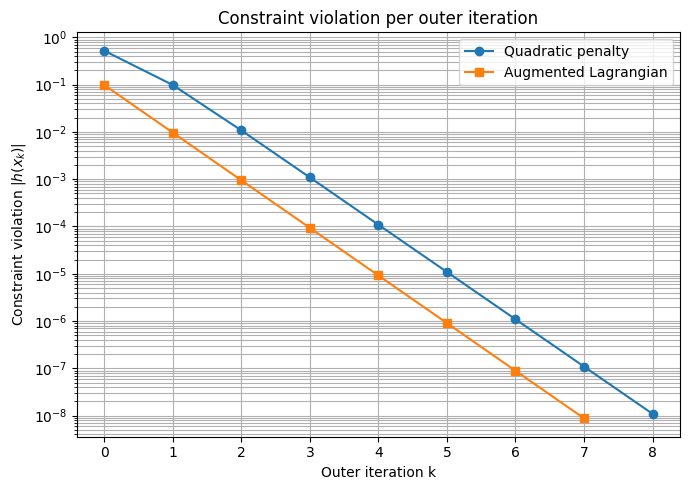

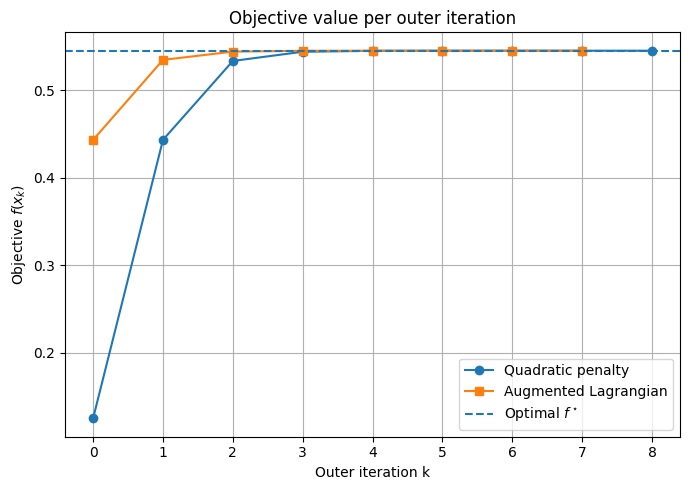

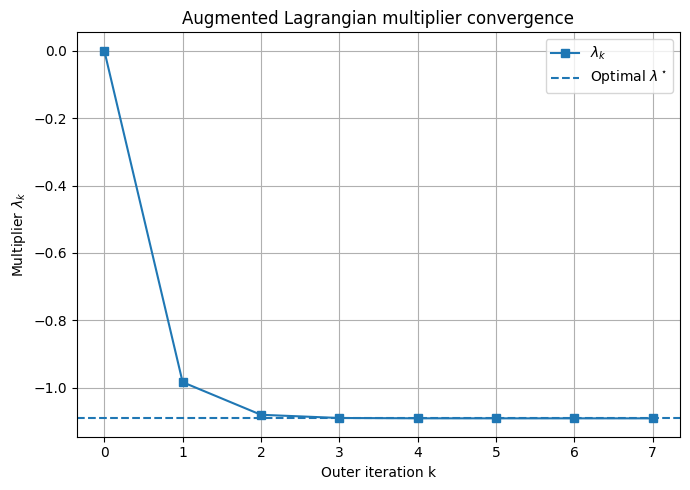

In [9]:
print("x* =", x_star, " f* =", f_star, " lambda* =", nu_star)

plt.figure(figsize=(7,5))
plt.semilogy(pen_df["k"], pen_df["abs_h"], marker="o", label="Quadratic penalty")
plt.semilogy(aug_df["k"], aug_df["abs_h"], marker="s", label="Augmented Lagrangian")
plt.xlabel("Outer iteration k")
plt.ylabel(r"Constraint violation $|h(x_k)|$")
plt.title("Constraint violation per outer iteration")
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.savefig("q2_violation.png", dpi=300)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(pen_df["k"], pen_df["f"], marker="o", label="Quadratic penalty")
plt.plot(aug_df["k"], aug_df["f"], marker="s", label="Augmented Lagrangian")
plt.axhline(f_star, linestyle="--", label=r"Optimal $f^\star$")
plt.xlabel("Outer iteration k")
plt.ylabel(r"Objective $f(x_k)$")
plt.title("Objective value per outer iteration")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("q2_objective.png", dpi=300)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(aug_df["k"], aug_df["lambda"], marker="s", label=r"$\lambda_k$")
plt.axhline(nu_star, linestyle="--", label=r"Optimal $\lambda^\star$")
plt.xlabel("Outer iteration k")
plt.ylabel(r"Multiplier $\lambda_k$")
plt.title("Augmented Lagrangian multiplier convergence")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("q2_lambda.png", dpi=300)
plt.show()



## Results and interpretation

The exact solution is $(6/11,3/11,2/11)\approx(0.545455,0.272727,0.181818)$, with $f^*=6/11$ and multiplier $-12/11$.

| Method | Subproblems | Final penalty parameter | Final absolute constraint residual |
|---|---:|---:|---:|
| Quadratic penalty | 9 | $10^8$ | $1.090909\times10^{-8}$ |
| Augmented Lagrangian | 8 | 10 | $8.761356\times10^{-9}$ |

Both objective values approach the constrained optimum from below because intermediate points need not satisfy the equality. The augmented Lagrangian reaches a slightly smaller residual using a fixed moderate penalty and one fewer subproblem. Its multiplier approaches the analytical KKT multiplier. In contrast, the quadratic penalty uses increasingly large coefficients, which can worsen the conditioning of the linear system.

This is a comparison of exact subproblem solutions with chosen schedules, not a general runtime benchmark. The displayed residuals and rounded objective values do not imply exact feasibility.